This program will implement Value Iteration and Policy Iteration.

In **Policy Iteration**, the current policy $\pi(a|s)$ is first evaluated by computing $V^\pi(s)$ for all states until the value function converges. Then, the policy is improved by making it greedy with respect to the current value function:

$$
\pi_{\text{new}}(s)
=
\arg\max_{a \in \mathcal A}
\sum_{s',r}
p(s',r|s,a)
\left[
r+\gamma V^\pi(s')
\right].
$$

These two steps are repeated until the policy no longer changes.

In **Value Iteration**, policy evaluation and policy improvement are combined into a single update. For each state, the algorithm directly selects the action that gives the highest expected return:

$$
V_{k+1}(s)
=
\max_{a \in \mathcal A}
\sum_{s',r}
p(s',r|s,a)
\left[
r+\gamma V_k(s')
\right].
$$

After the value function converges, the optimal policy is obtained by choosing the greedy action in each state.

We start with policy update

In [1]:
import numpy as np

In [2]:
states = np.array([
    [-1,0,1,0],
    [0,0,0,0],
    [-1,1,0,0],
    [0,0,0,0]
])

state_coordinates = [
    (row, col)
    for row in range(states.shape[0])
    for col in range(states.shape[1])
]

terminal_states = [s for s in state_coordinates if abs(states[s[0],s[1]]) == 1]

In [3]:
#constrain actions to moving in only one direction
actions = [
    (-1, 0),  # up
    (1, 0),   # down
    (0, -1),  # left
    (0, 1)    # right
]

policy = {
    state: actions[np.random.choice(len(actions))]
    for state in state_coordinates
    if state not in terminal_states
}
# deterministic policy : for each state take the same action everytime

V = {
    state: 0.0
    for state in state_coordinates
}

In [4]:
transitions = {}

for state in state_coordinates:

    if state in terminal_states:
        continue

    transitions[state] = {}

    for action in actions:

        transitions[state][action] = {}

        # Example stochastic model:
        # 80% intended action
        # 10% slip one way
        # 10% slip the other way

        if action == (-1, 0):       # up
            outcomes = [
                ((-1, 0), 0.8),
                ((0, -1), 0.1),
                ((0, 1), 0.1)
            ]

        elif action == (1, 0):      # down
            outcomes = [
                ((1, 0), 0.8),
                ((0, -1), 0.1),
                ((0, 1), 0.1)
            ]

        elif action == (0, -1):     # left
            outcomes = [
                ((0, -1), 0.8),
                ((-1, 0), 0.1),
                ((1, 0), 0.1)
            ]

        elif action == (0, 1):      # right
            outcomes = [
                ((0, 1), 0.8),
                ((-1, 0), 0.1),
                ((1, 0), 0.1)
            ]

        for actual_action, probability in outcomes:

            candidate_state = tuple(x + y for x, y in zip(state, actual_action))

            # If move goes outside grid, stay in place
            if candidate_state not in state_coordinates:
                candidate_state = state

            # Add probability rather than overwrite it
            transitions[state][action][candidate_state] = (transitions[state][action].get(candidate_state, 0.0)+ probability)

# p(s',r | s,a) = 1 except when on a terminal state (purely deterministic for now)
# the terminal states are ommitted

In [5]:
def get_reward(state):
    reward = states[state[0],state[1]]
    return reward

The value update is :
$$ V_{k+1}(s)
\leftarrow
\sum_a \pi(a|s)
\sum_{s'}
p(s'|s,a)
\left[
R(s,a,s')
+
\gamma V_k(s')
\right]$$

The policy is deterministic, therefore $\sum_a \pi(a|s)=1$ i.e if the agent is at state s the policy it will choose the same action a every time so that single action given s has probability 1

$$ V_{k+1}(s)
\leftarrow
\sum_{s'}
p(s'|s,a)
\left[
R(s,a,s')
+
\gamma V_k(s')
\right]$$

In [6]:
rng = np.random.default_rng(1234)
def get_next_state(state, action):

    outcomes = transitions[state][action] # the actual outcome

    next_states = list(outcomes.keys())
    probabilities = list(outcomes.values())

    next_state = rng.choice(
        len(next_states),
        p=probabilities
    )

    return next_states[next_state]

gamma = 0.99

def get_value(state):
    value = 0.0

    action = policy[state]
    for next_state, probability in transitions[state][action].items():
        value += probability * (
            get_reward(next_state)
            + gamma * V[next_state]
        )

    return value

def policy_evaluation(theta=1e-6):

    while True:

        delta = 0.0

        for state in state_coordinates:

            if state in terminal_states:
                continue

            old_value = V[state]

            V_new = get_value(state)

            V[state] = V_new

            delta = max(
                delta,
                abs(V_new - old_value)
            )

        if delta < theta:
            break

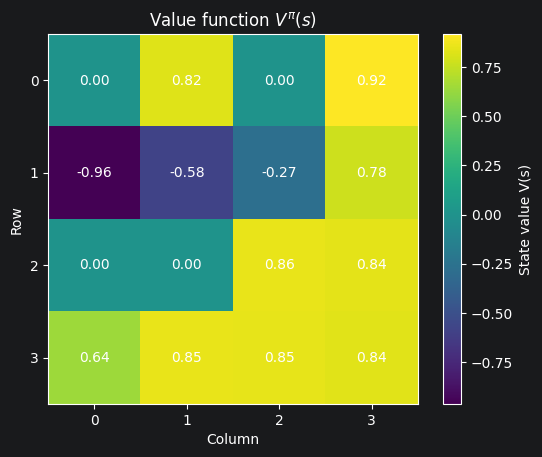

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Run policy evaluation first
policy_evaluation()

# Convert the V dictionary into a 2D array
V_grid = np.zeros(states.shape)

for state, value in V.items():
    V_grid[state] = value

# Plot heatmap
plt.imshow(V_grid)
plt.colorbar(label="State value V(s)")

# Write values inside cells
for row in range(V_grid.shape[0]):
    for col in range(V_grid.shape[1]):
        plt.text(
            col,
            row,
            f"{V_grid[row, col]:.2f}",
            ha="center",
            va="center"
        )

plt.xticks(range(states.shape[1]))
plt.yticks(range(states.shape[0]))
plt.xlabel("Column")
plt.ylabel("Row")
plt.title(r"Value function $V^\pi(s)$")
plt.show()

In [8]:
def policy_improvement():

    policy_stable = True

    for state in state_coordinates:

        if state in terminal_states:
            continue

        old_action = policy[state]

        action_values = {}

        for action in actions:

            q = 0.0

            for next_state, probability in transitions[state][action].items():

                q += probability * (
                    get_reward(next_state)
                    + gamma * V[next_state]
                )

            action_values[action] = q

        best_action = max(action_values,key=action_values.get)

        policy[state] = best_action

        if best_action != old_action:
            policy_stable = False

    return policy_stable

In [9]:
while True:

    policy_evaluation()

    policy_stable = policy_improvement()

    if policy_stable:
        break

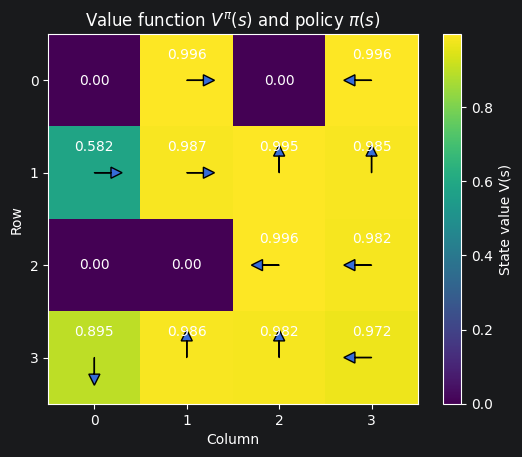

In [11]:
import matplotlib.pyplot as plt
import numpy as np

V_grid = np.zeros(states.shape)

for state, value in V.items():
    V_grid[state] = value

plt.imshow(V_grid)
plt.colorbar(label="State value V(s)")

for state in state_coordinates:

    row, col = state

    if state in terminal_states:
        plt.text(
            col, row,
            f"{V[state]:.2f}",
            ha="center",
            va="center"
        )
        continue

    drow, dcol = policy[state]

    plt.arrow(
        col,
        row,
        dcol * 0.3,
        drow * 0.3,
        head_width=0.12,
        head_length=0.12,
        length_includes_head=True
    )

    plt.text(
        col,
        row - 0.28,
        f"{V[state]:.3f}",
        ha="center",
        va="center"
    )

plt.xticks(range(states.shape[1]))
plt.yticks(range(states.shape[0]))
plt.xlabel("Column")
plt.ylabel("Row")
plt.title(r"Value function $V^\pi(s)$ and policy $\pi(s)$")
plt.show()